# SInERT observed-only EDA
Existing Parquets only; no ingestion, models or materialized windows. All parameter logic, plots and report generation live in `smartgrid.features.behaviour`. Every result reports excluded imputed counts. The inferred academic calendar is **PROVISIONAL**, pending the supervisor's real calendar.

In [1]:
from smartgrid.features.behaviour import (
    load_eda_data, present, write_eda_report, cumulative_energy, base_load,
    peak_demand, power_comparisons, site_behaviour, provisional_vacation_weeks,
    seasonality, autocorrelation, power_factor, load_duration, demand_divergence,
    meter_contributions, split_coverage,
)
context = load_eda_data()

Existing Parquets: EM=128,544 rows, all_meters=1,799,616 rows; EM imputed rows excluded=377.


## 1. Active energy: daily, weekly, monthly and annual

energy: excluded imputed=377; other missing observed=1


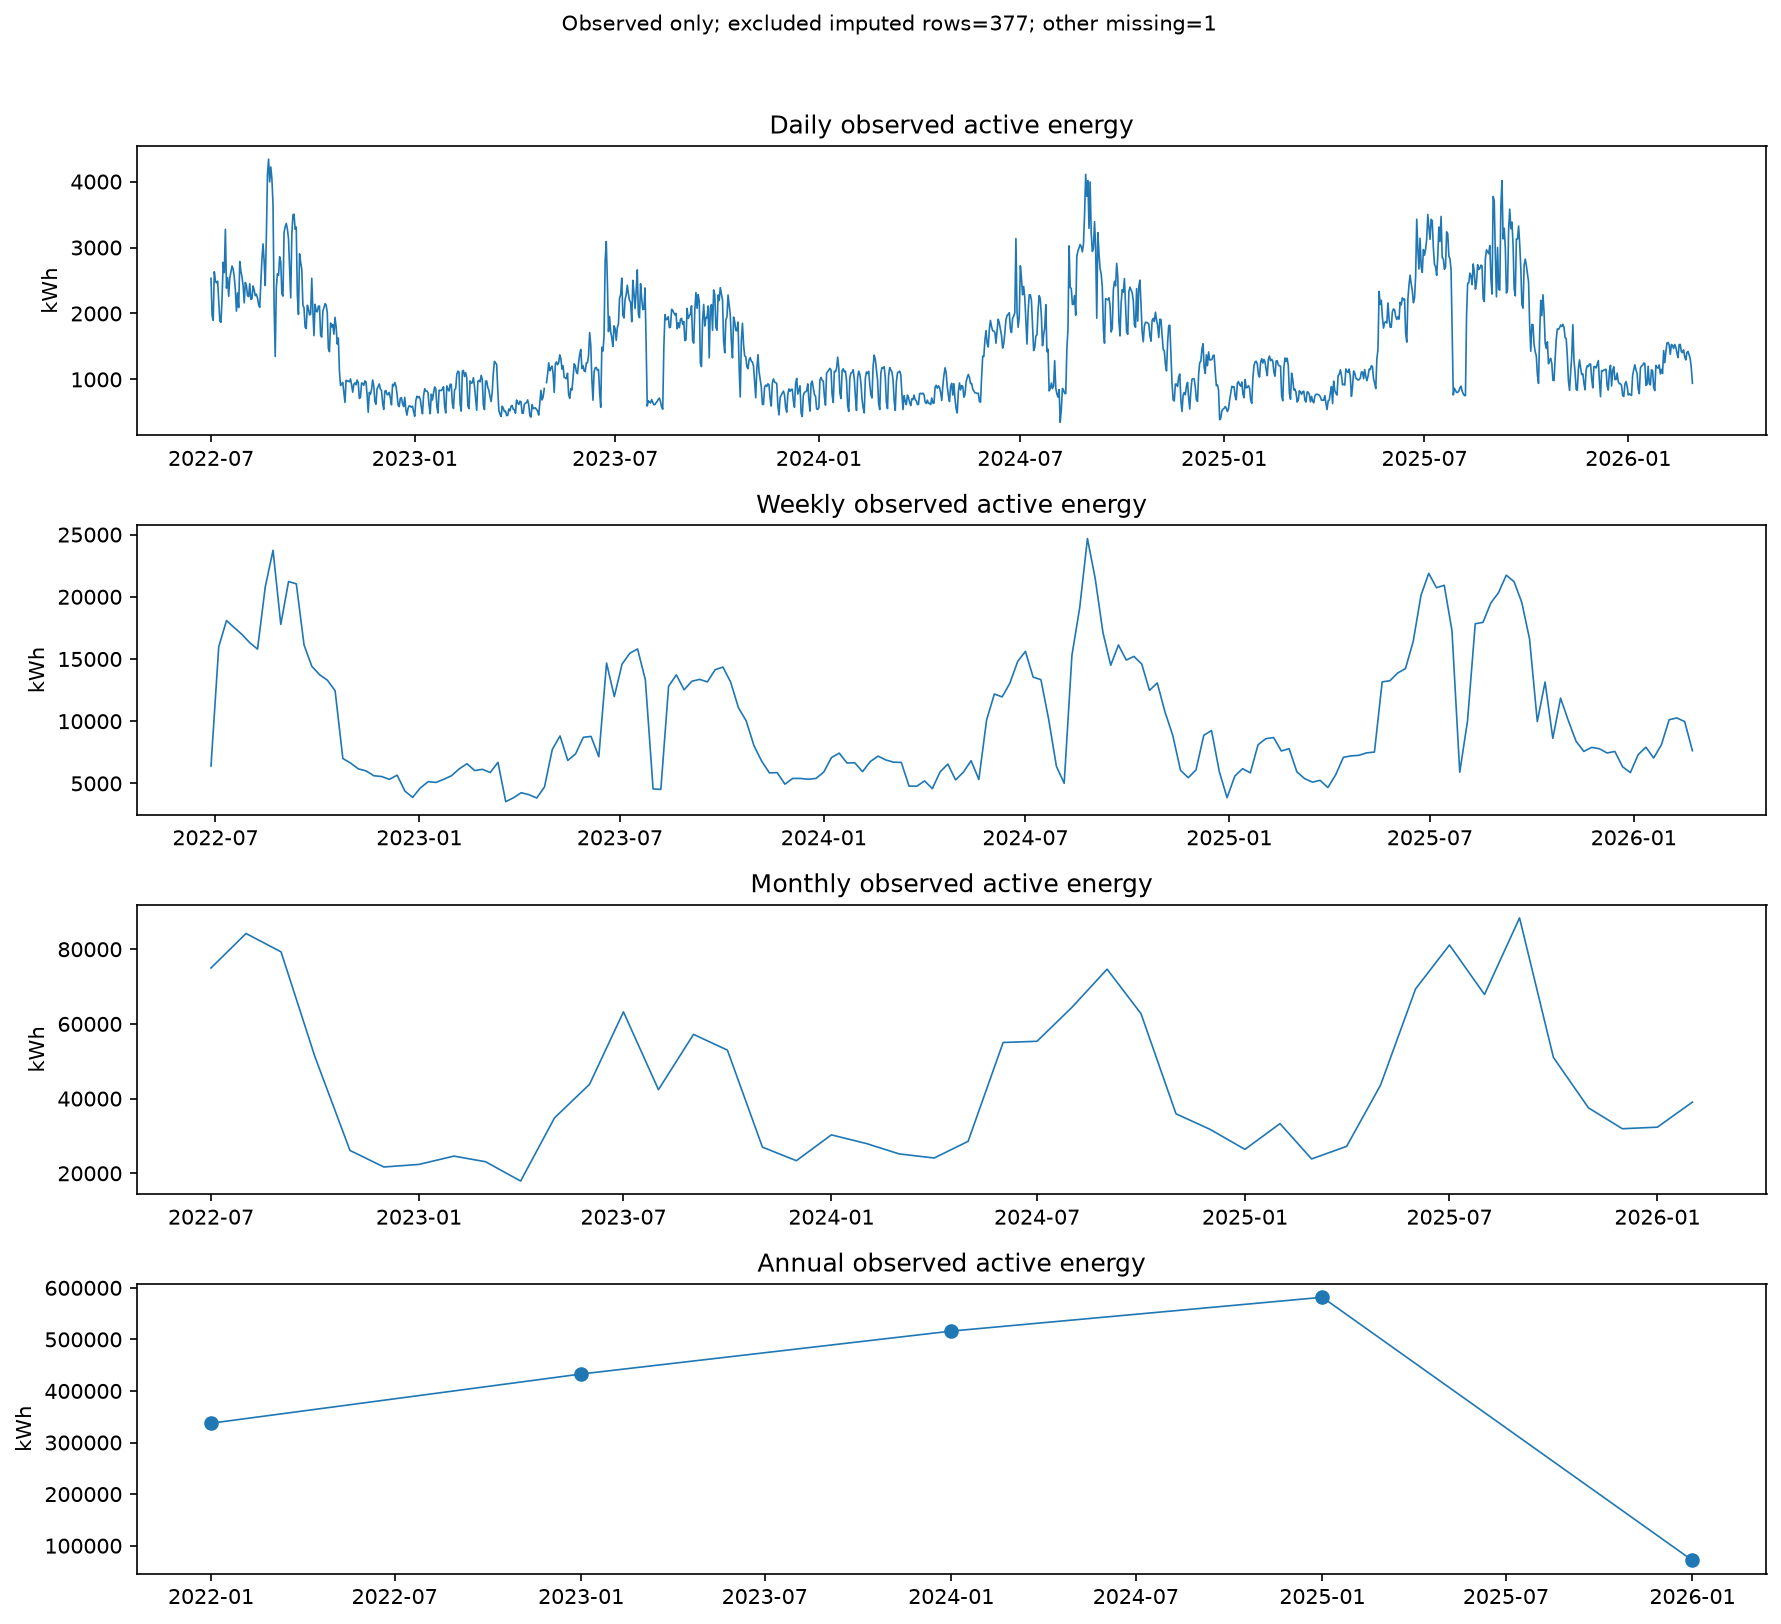

In [2]:
present(context, 'energy', cumulative_energy(context.em))

## 2. Daily base load and occurrence hour

base_load: excluded imputed=377; other missing observed=0


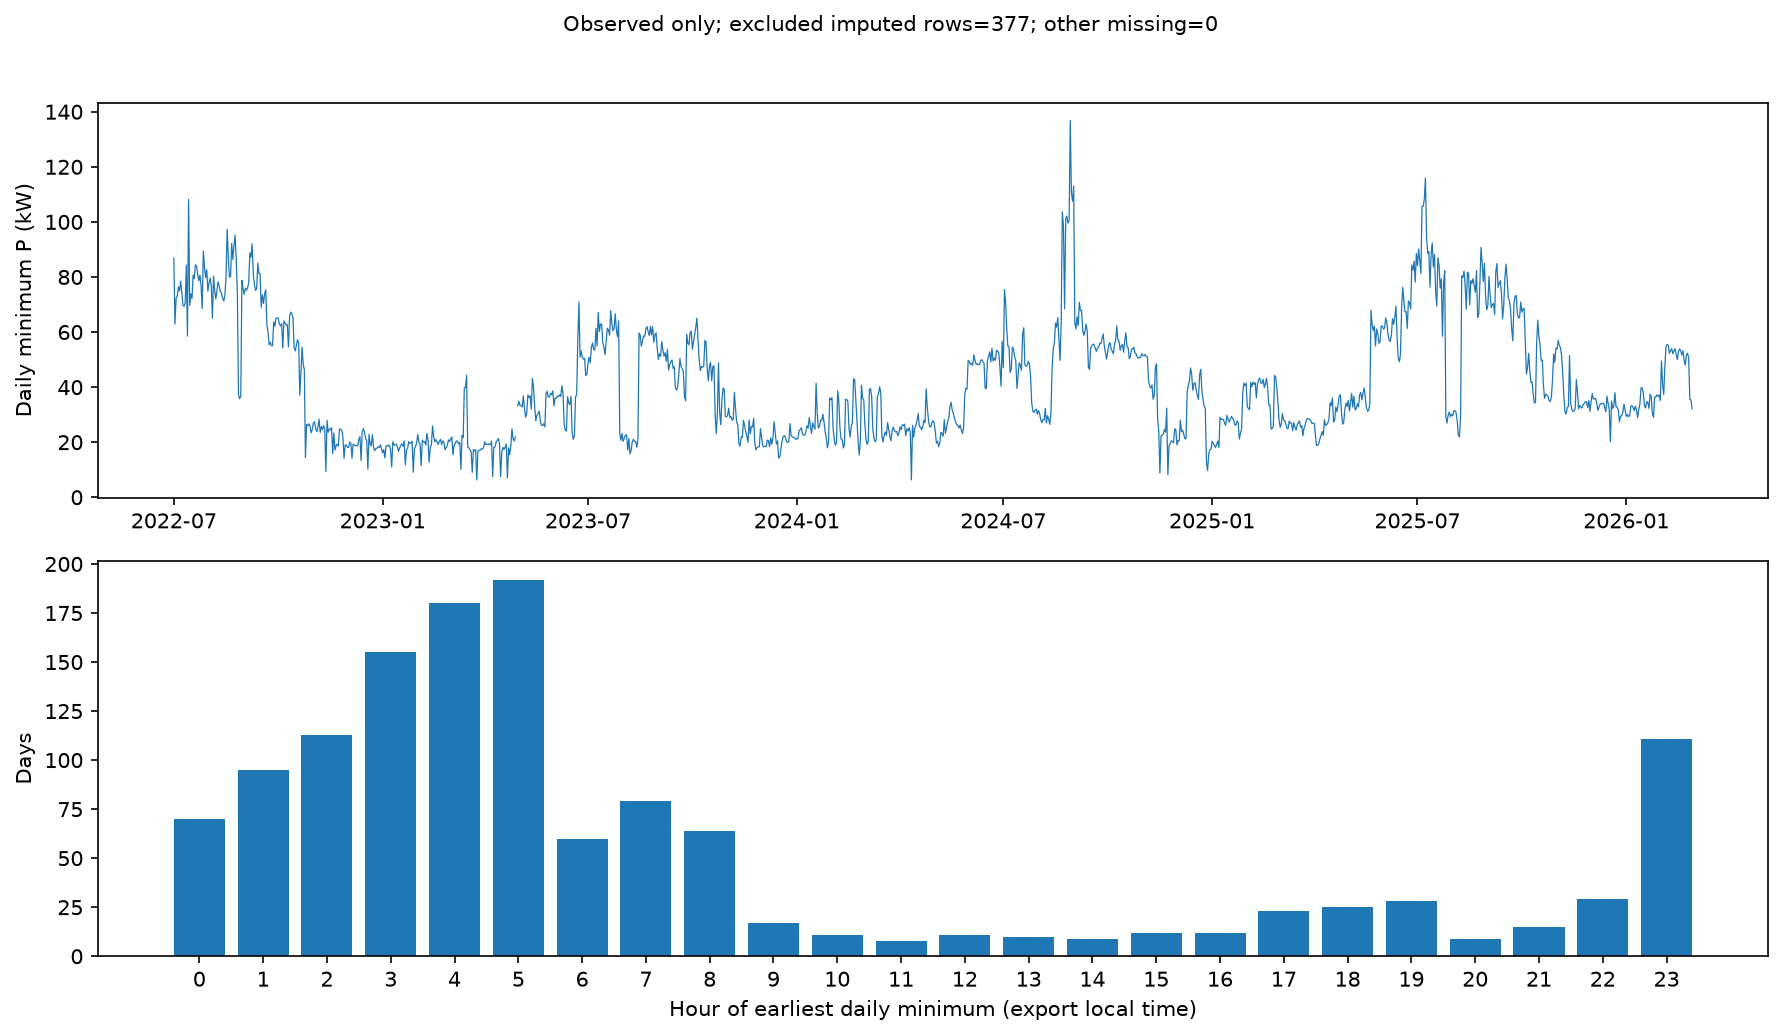

In [3]:
present(context, 'base_load', base_load(context.em))

## 3. Daily peaks and longest consecutive 90% band

peaks: excluded imputed=377; other missing observed=0


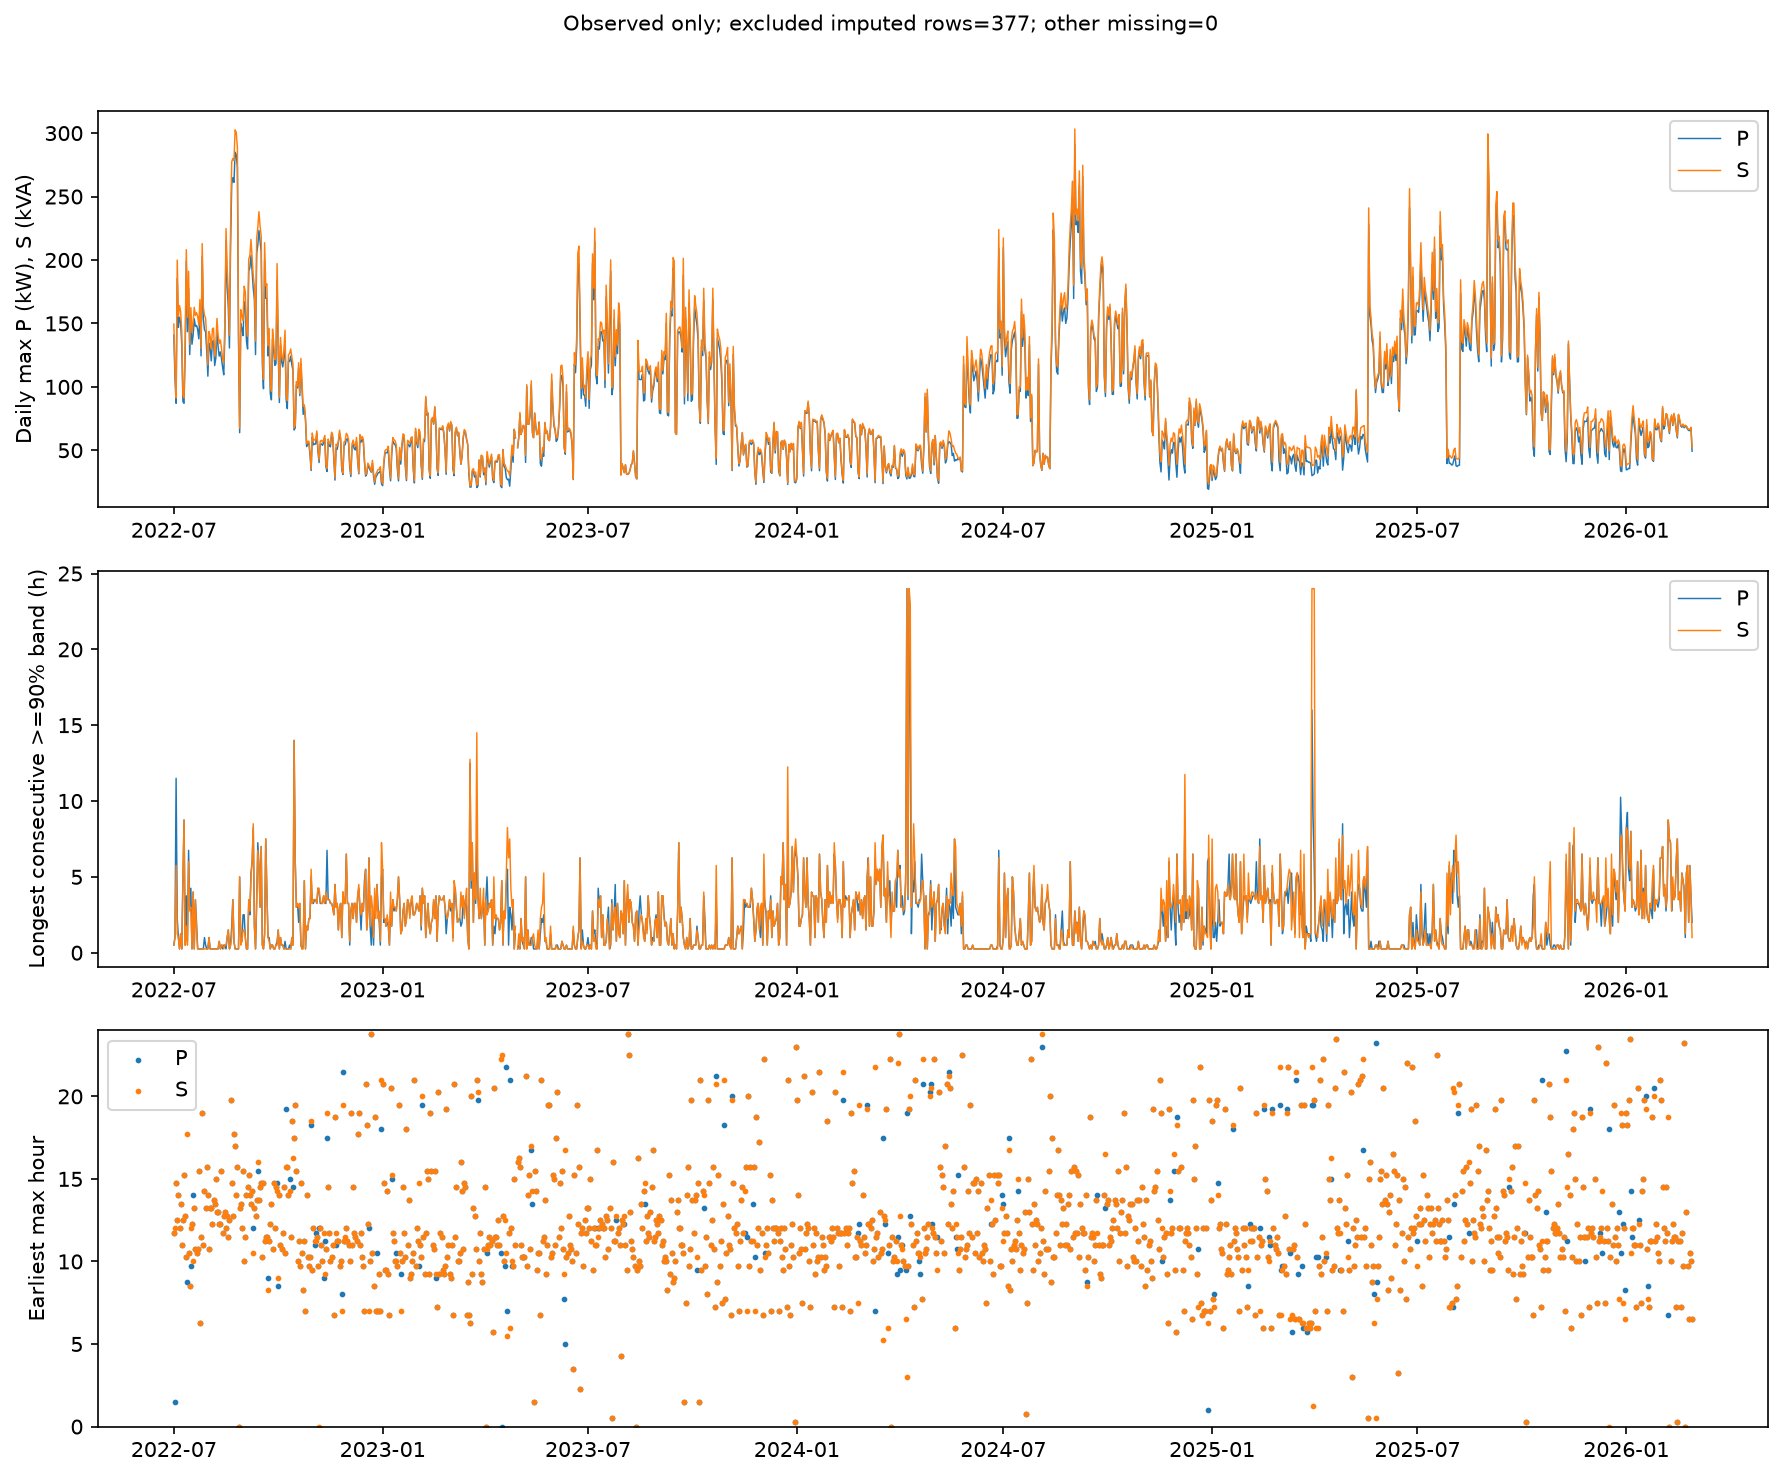

In [4]:
present(context, 'peaks', peak_demand(context.em))

## 4. Power comparisons, including PROVISIONAL academic proxies

power_comparisons: excluded imputed=377; other missing observed=0


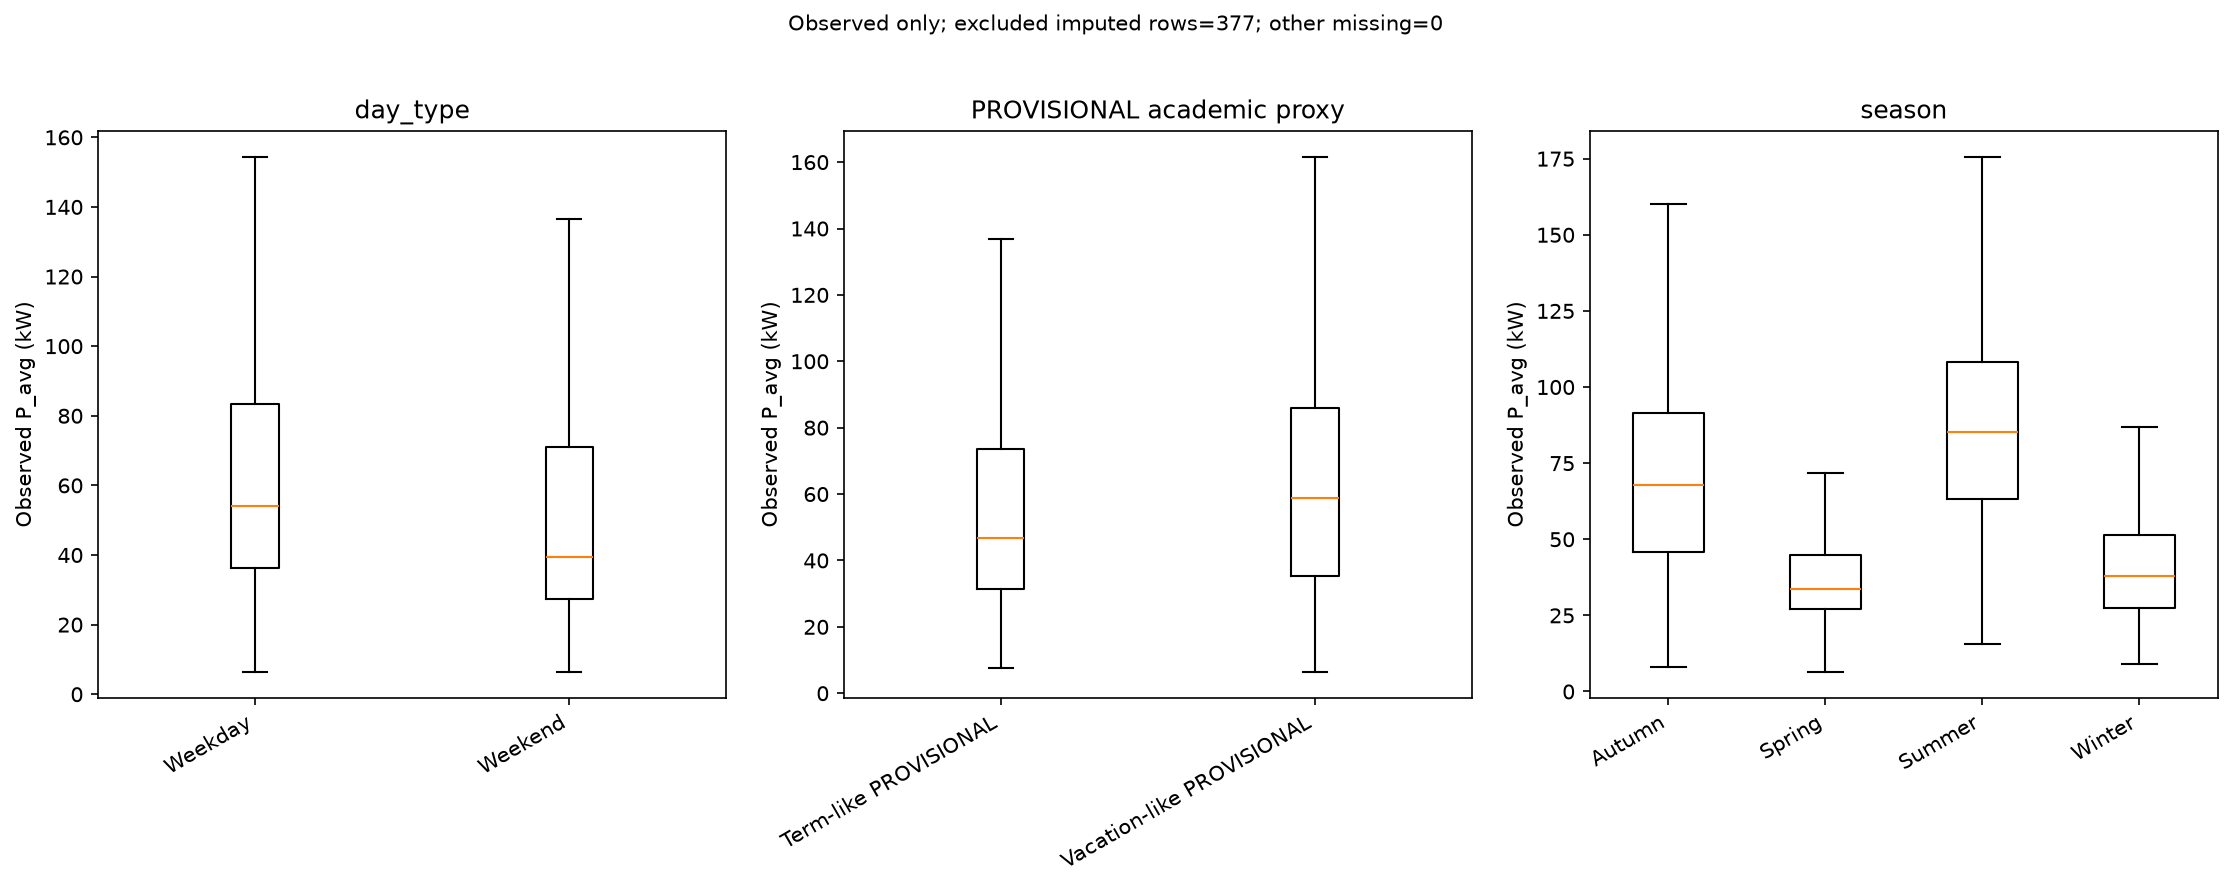

In [5]:
present(context, 'power_comparisons', power_comparisons(context.em))

## 5. Activity proxies and variability

activity: excluded imputed=377; other missing observed=0


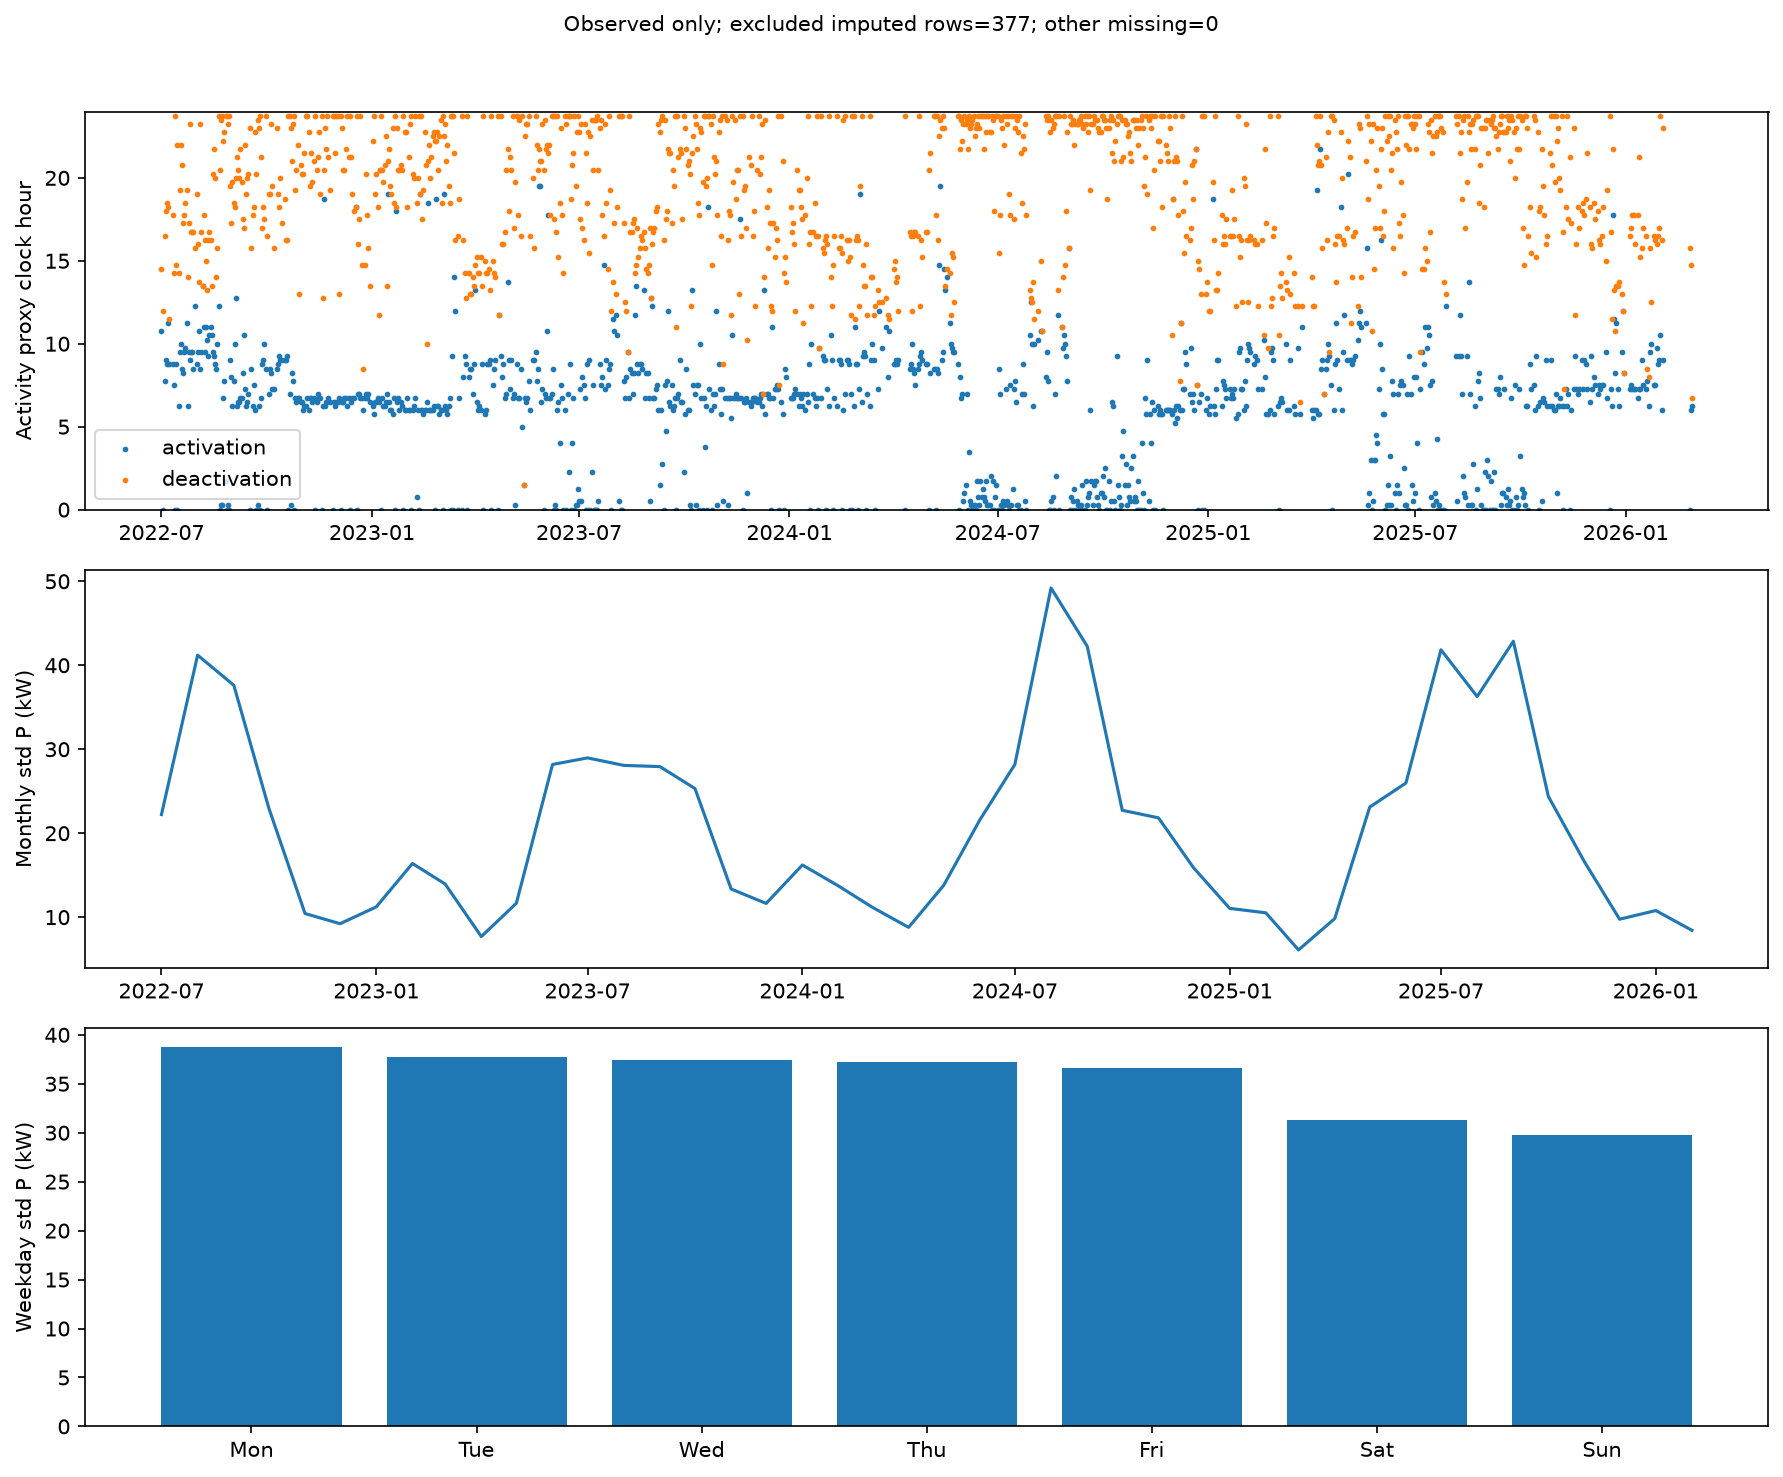

In [6]:
present(context, 'activity', site_behaviour(context.em))

## B. PROVISIONAL vacation-like weeks
This is NOT a SUP'COM academic calendar. Replace the PROVISIONAL inference with the supervisor's calendar.

PROVISIONAL_calendar: excluded imputed=377; other missing observed=0


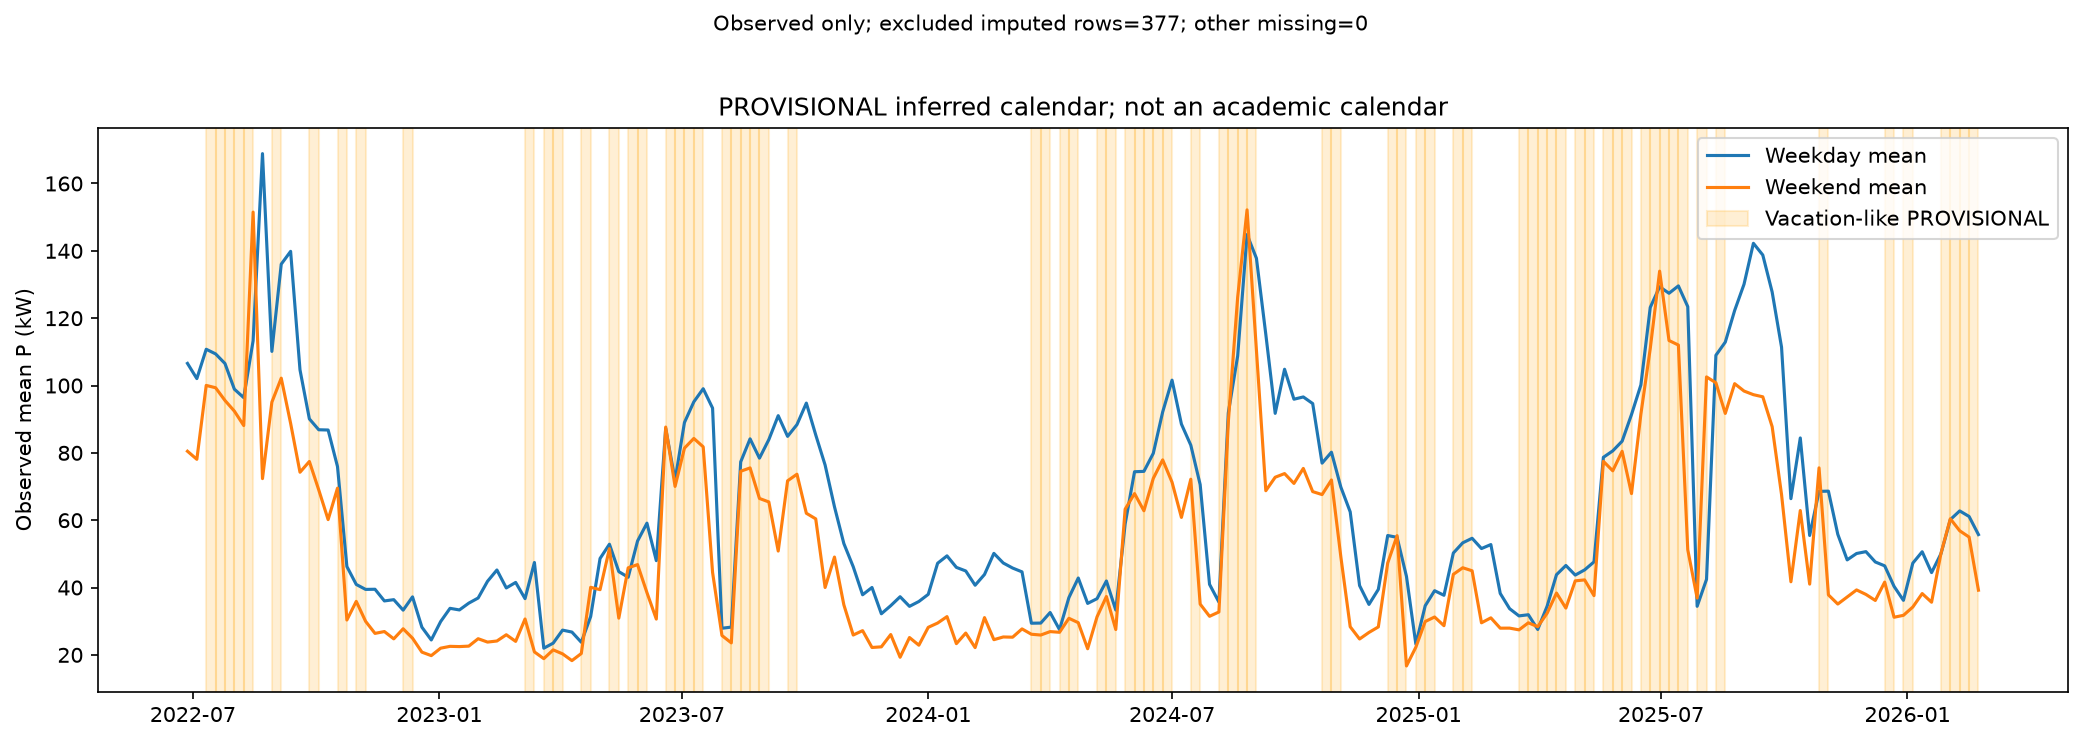

In [7]:
present(context, 'PROVISIONAL_calendar', provisional_vacation_weeks(context.em))

## 6. Monthly seasonality and seasonal daily profiles

seasonality: excluded imputed=377; other missing observed=1


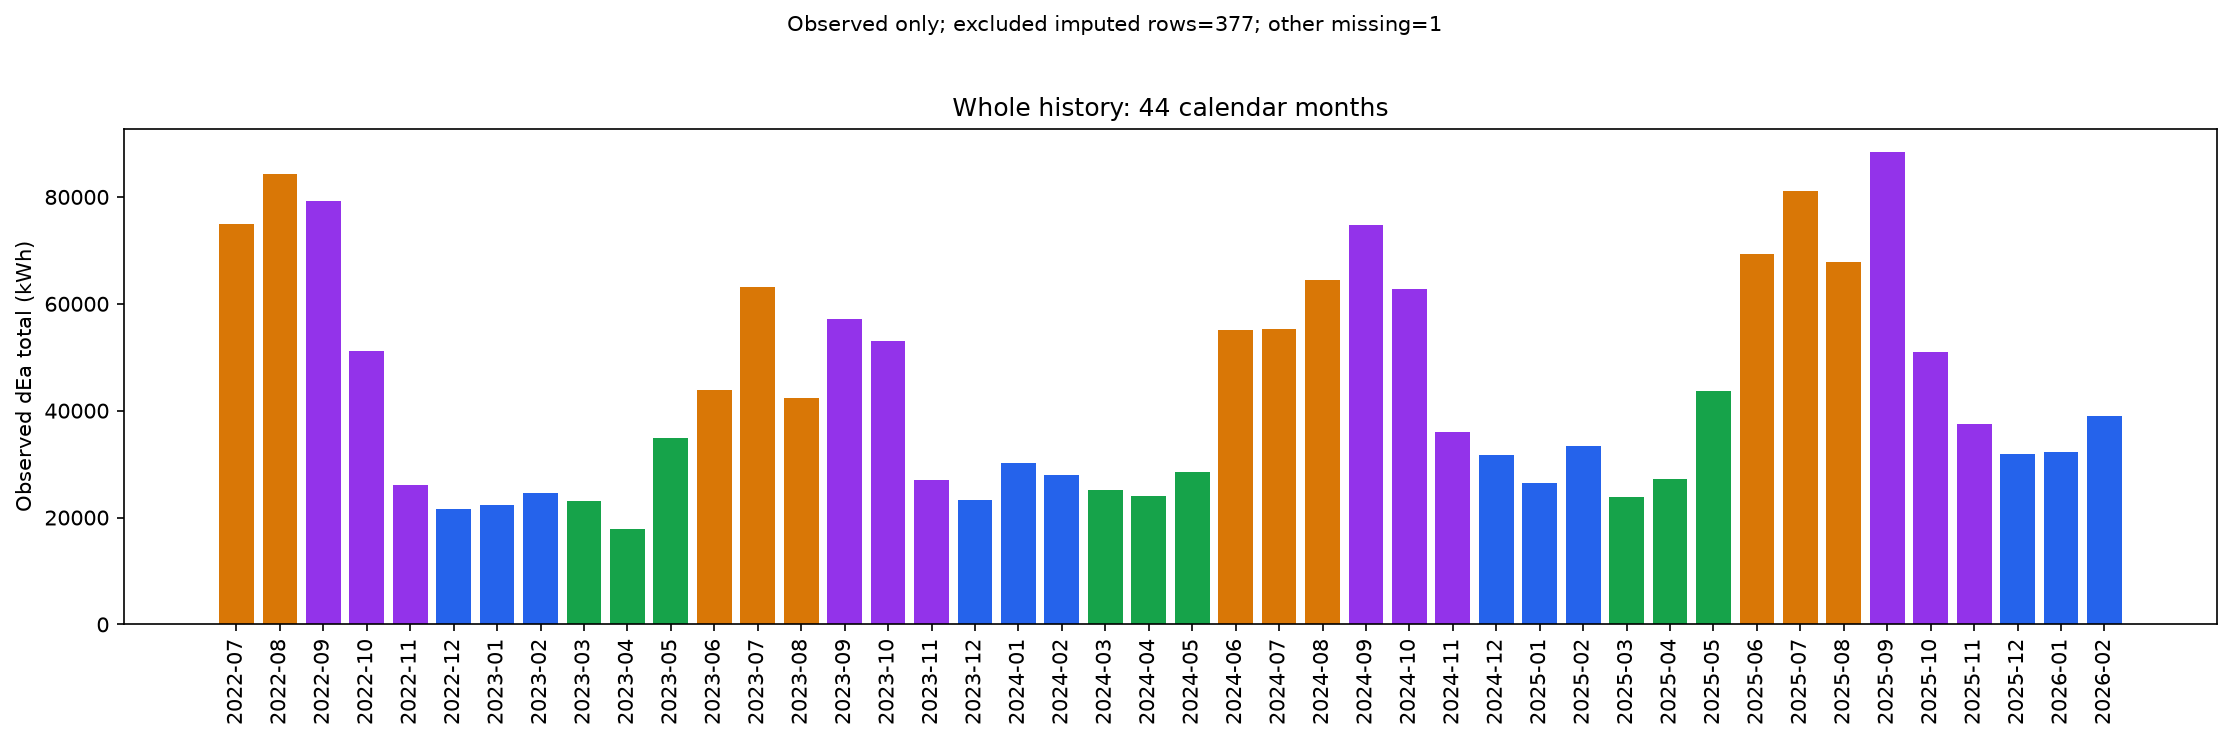

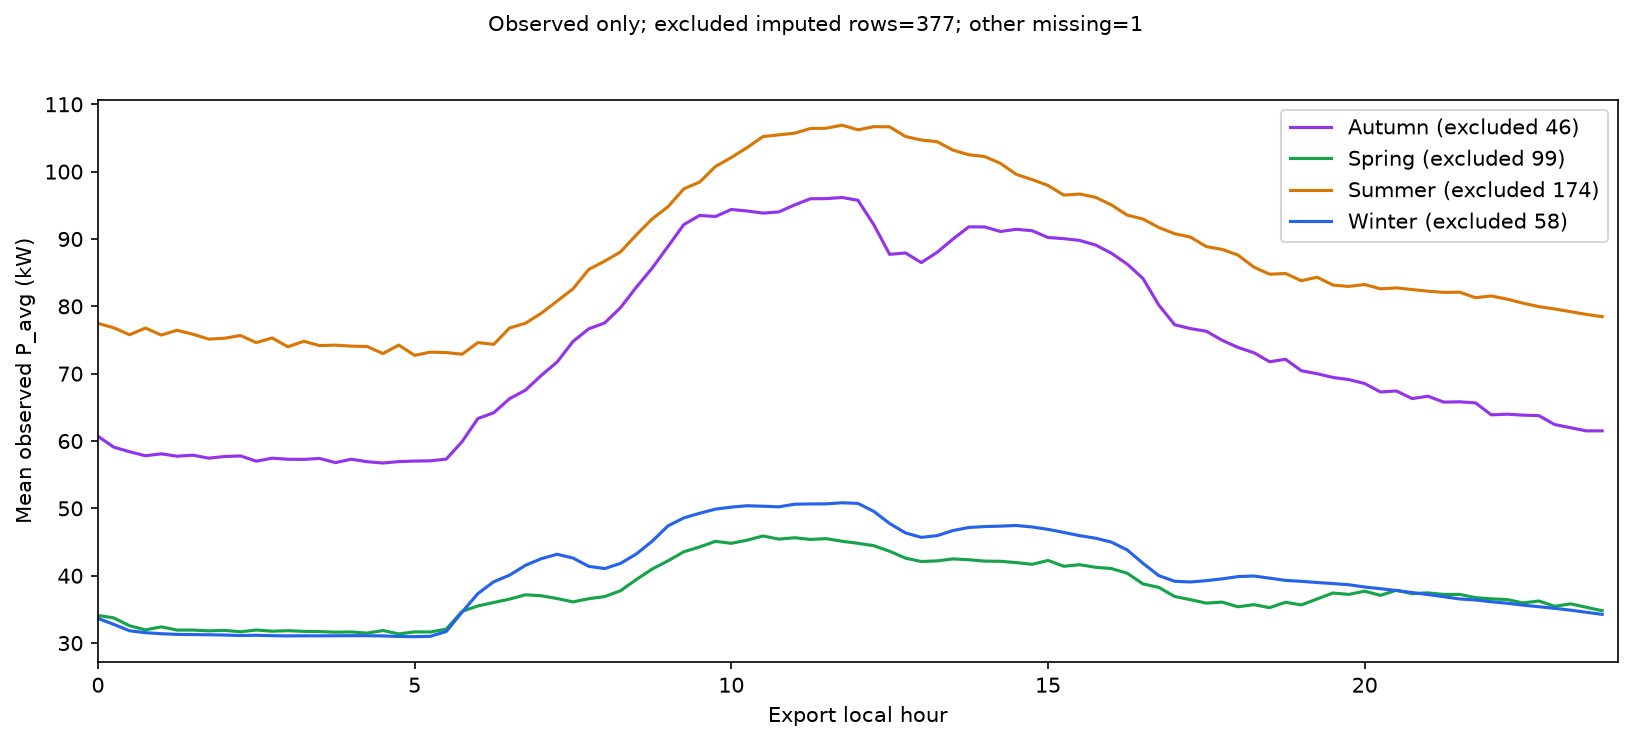

In [8]:
present(context, 'seasonality', seasonality(context.em))

## 7. Observed dEa autocorrelation on the original grid

autocorrelation: excluded imputed=377; other missing observed=1


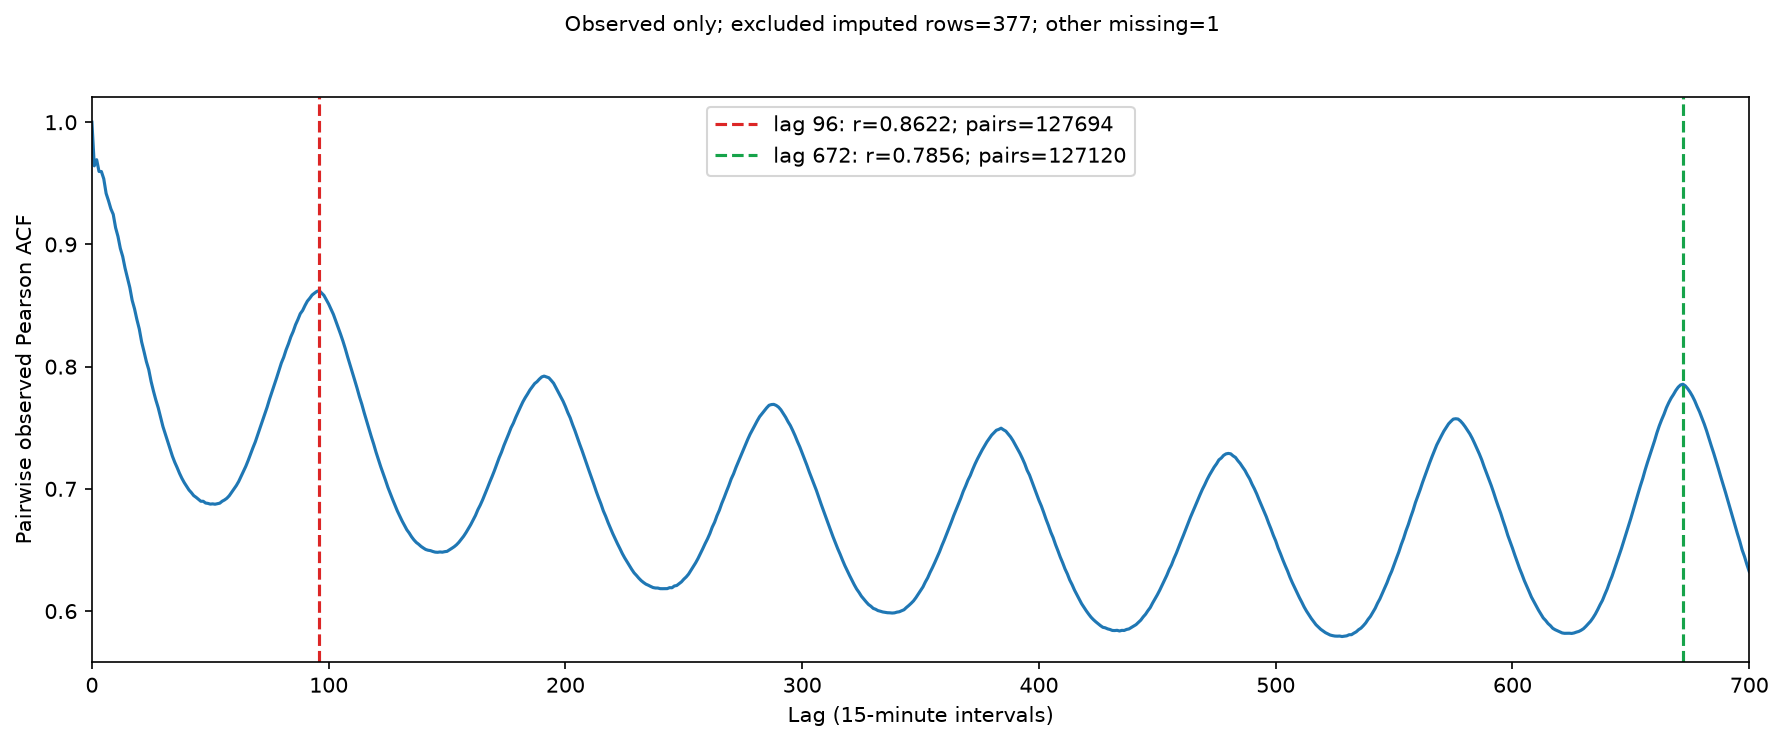

In [9]:
present(context, 'autocorrelation', autocorrelation(context.em))

## 8. Observed PF, alert candidates and positive Q

power_factor: excluded imputed=377; other missing observed=0


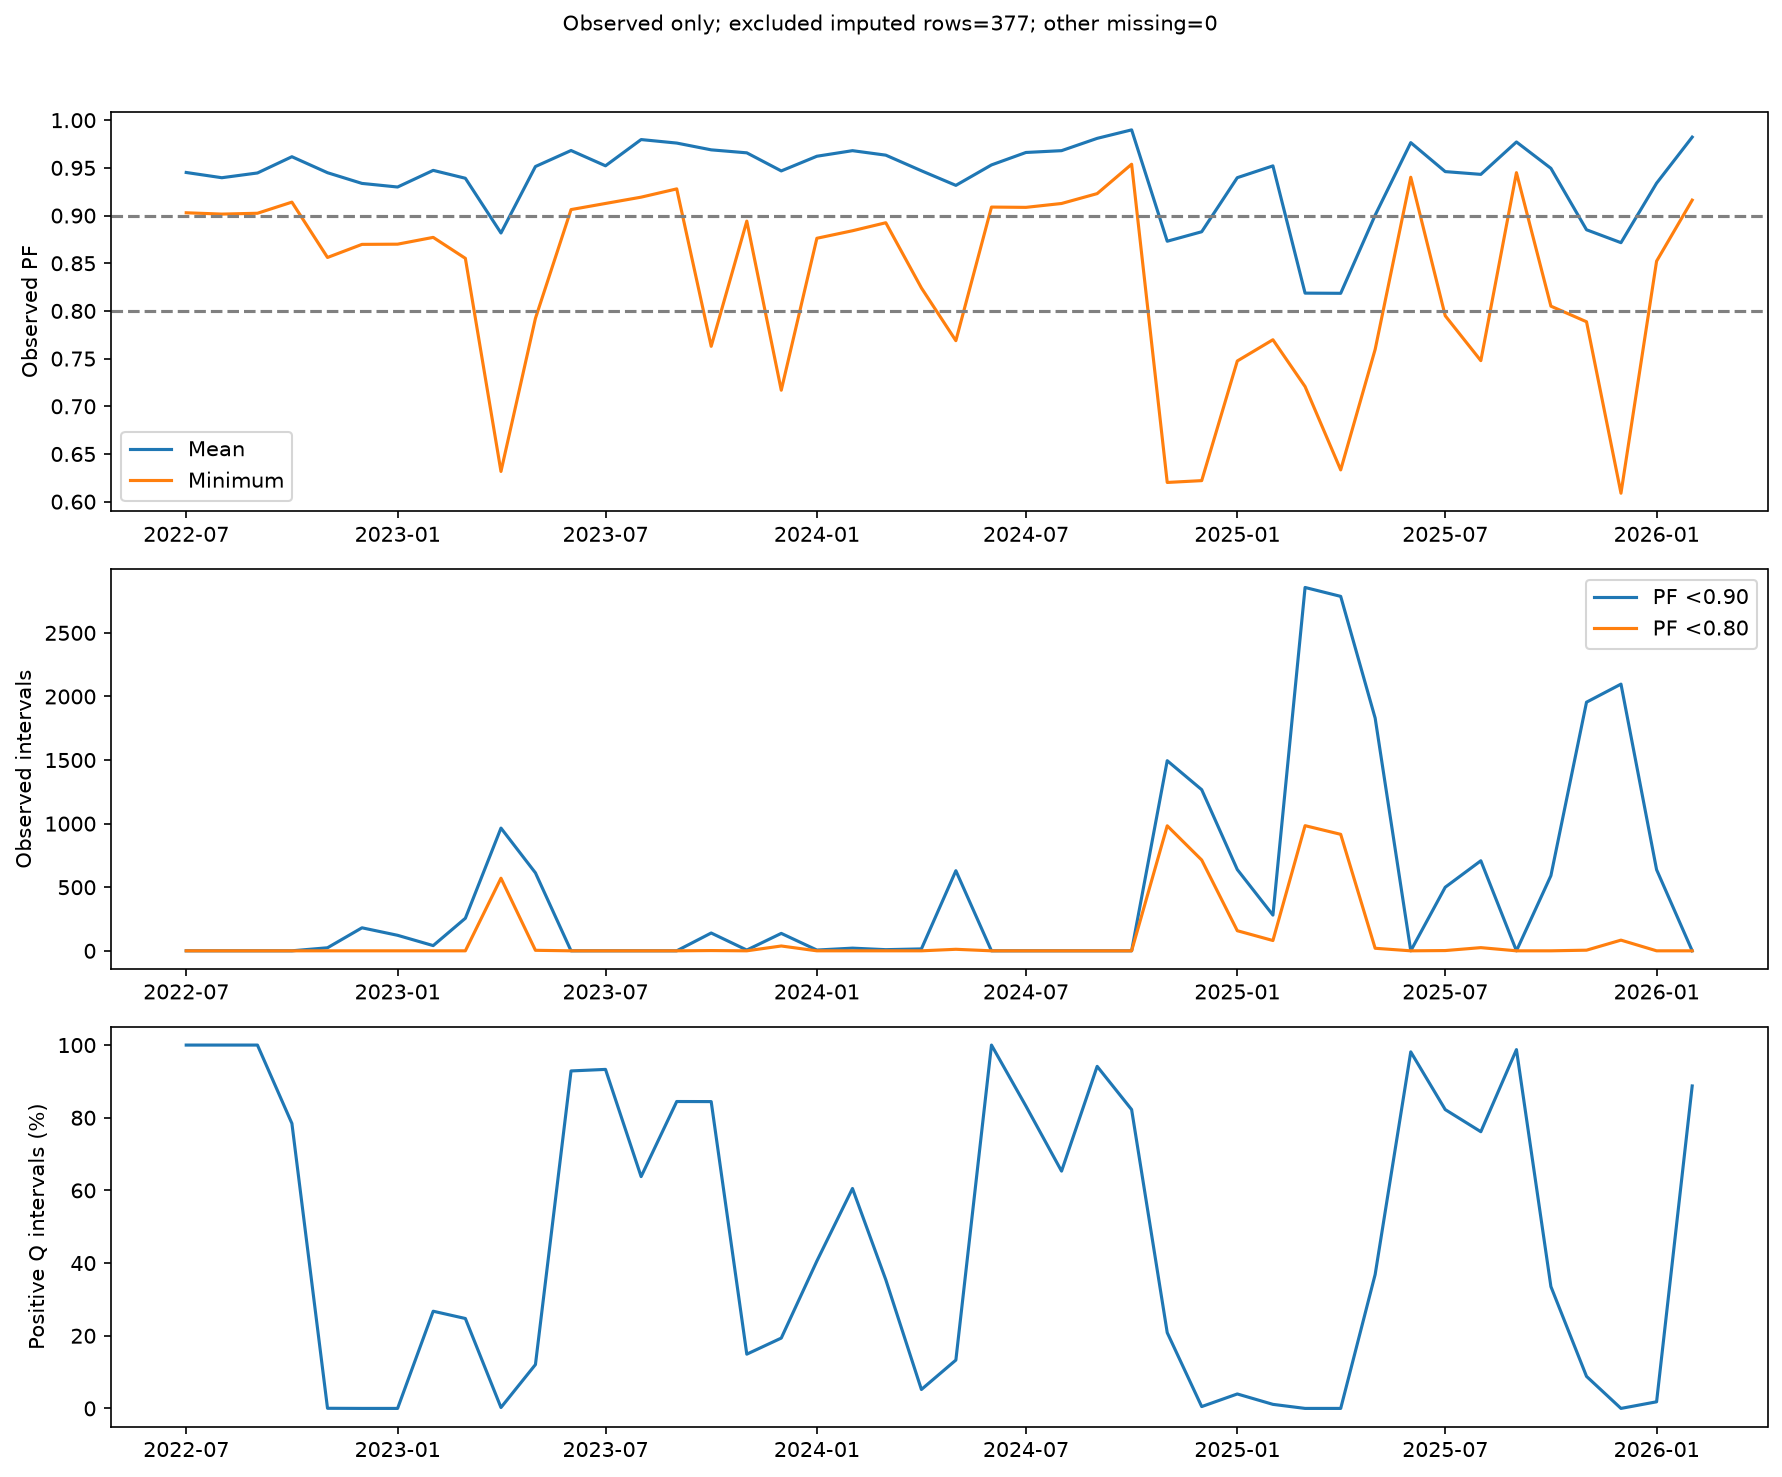

In [10]:
present(context, 'power_factor', power_factor(context.em))

## 9. S_avg load duration and the supplied 600 kVA reference

load_duration: excluded imputed=377; other missing observed=0


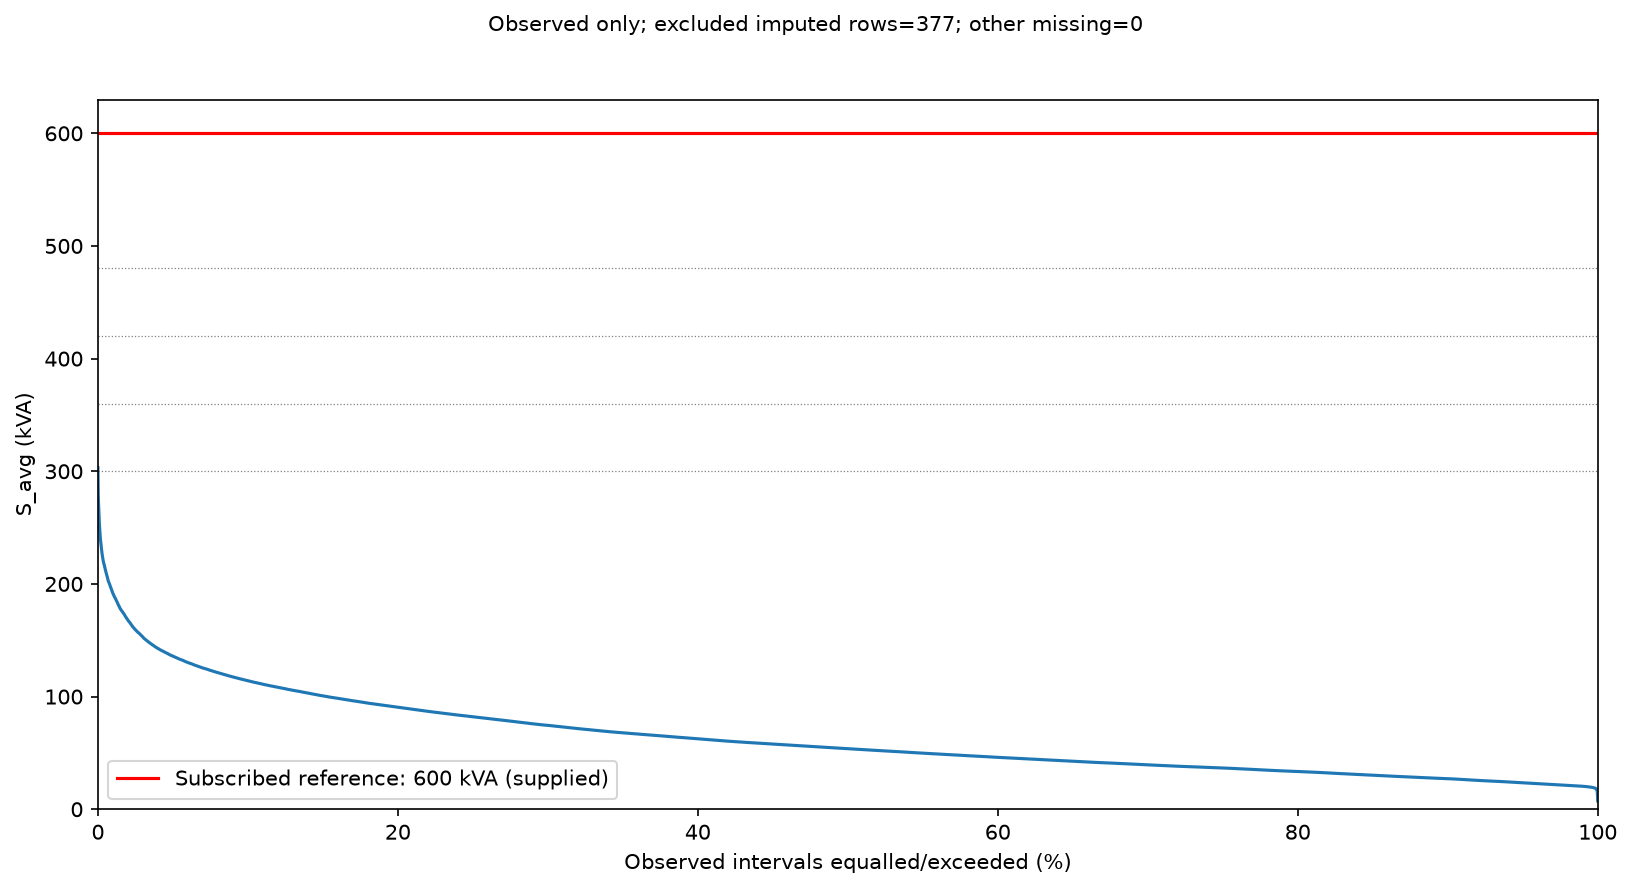

In [11]:
present(context, 'load_duration', load_duration(context.em))

## 10. Monthly demand-channel divergence: seasonal hypothesis

demand_divergence: excluded imputed=377; other missing observed=40


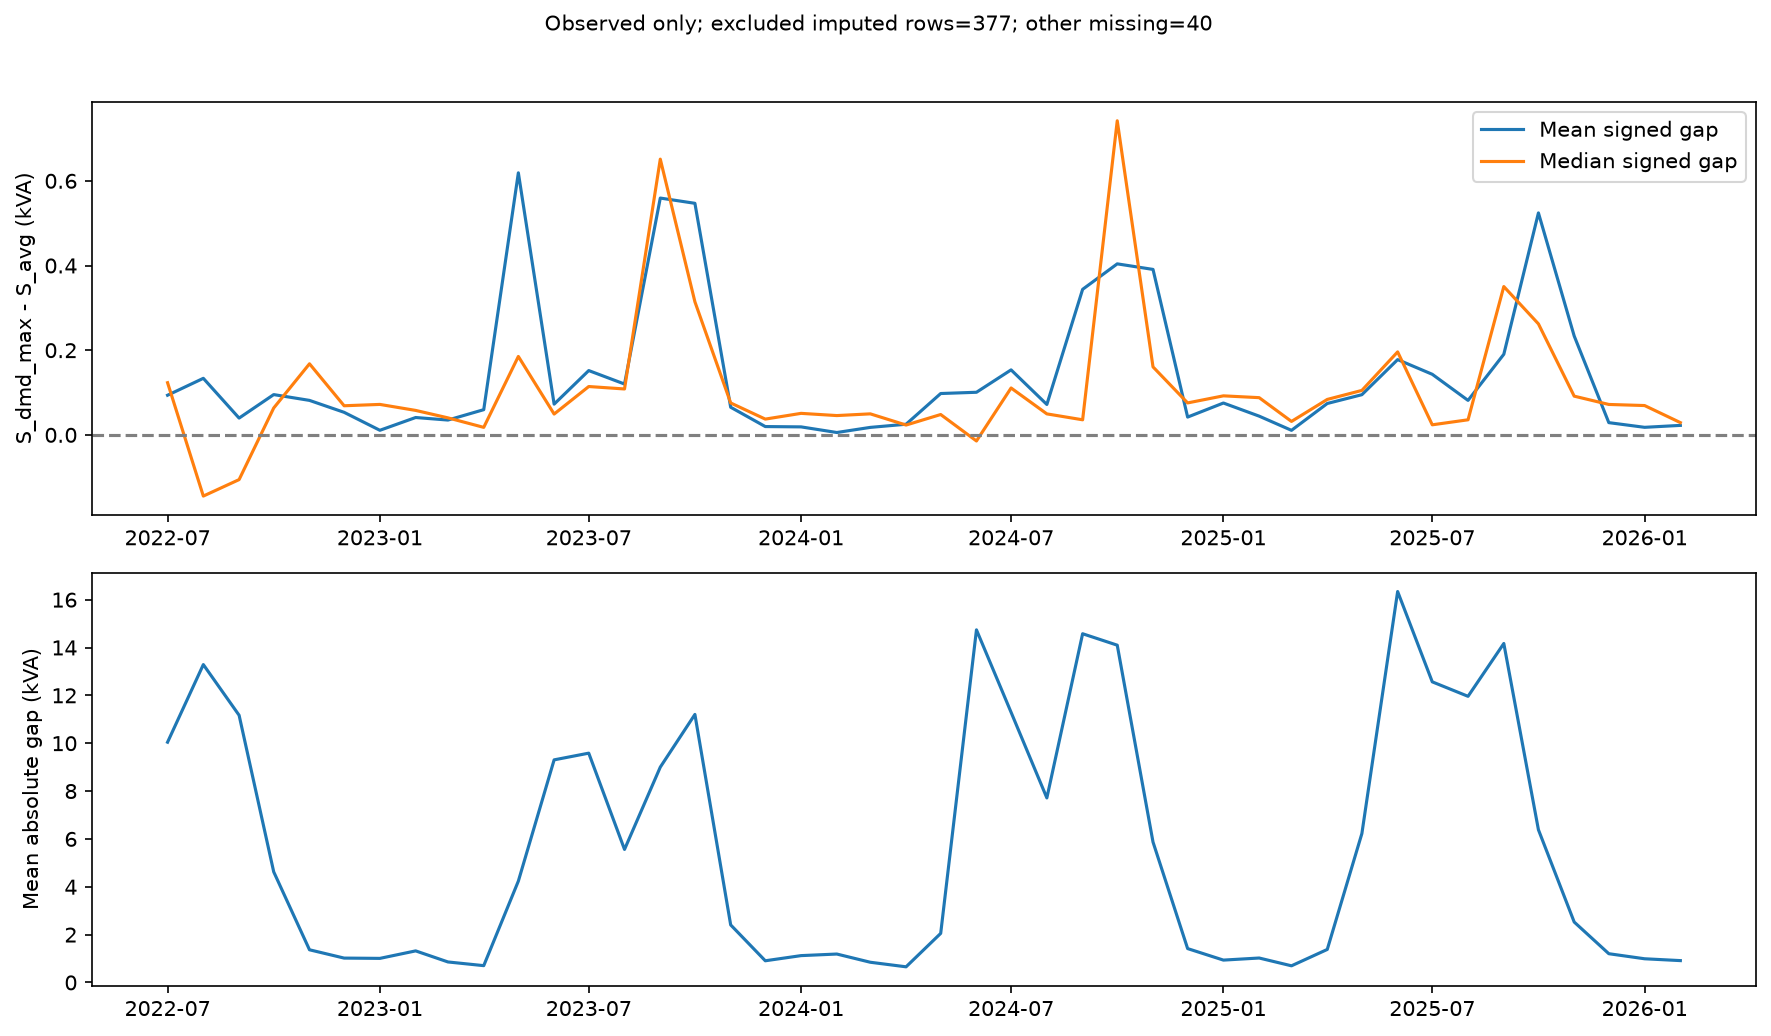

In [12]:
present(context, 'demand_divergence', demand_divergence(context.em))

## 11. Per-meter shares and seasonal changes
Parent and downstream meters overlap; their shares cannot be added as a disjoint allocation.

meter_contributions: excluded imputed=5,634; other missing observed=10,257


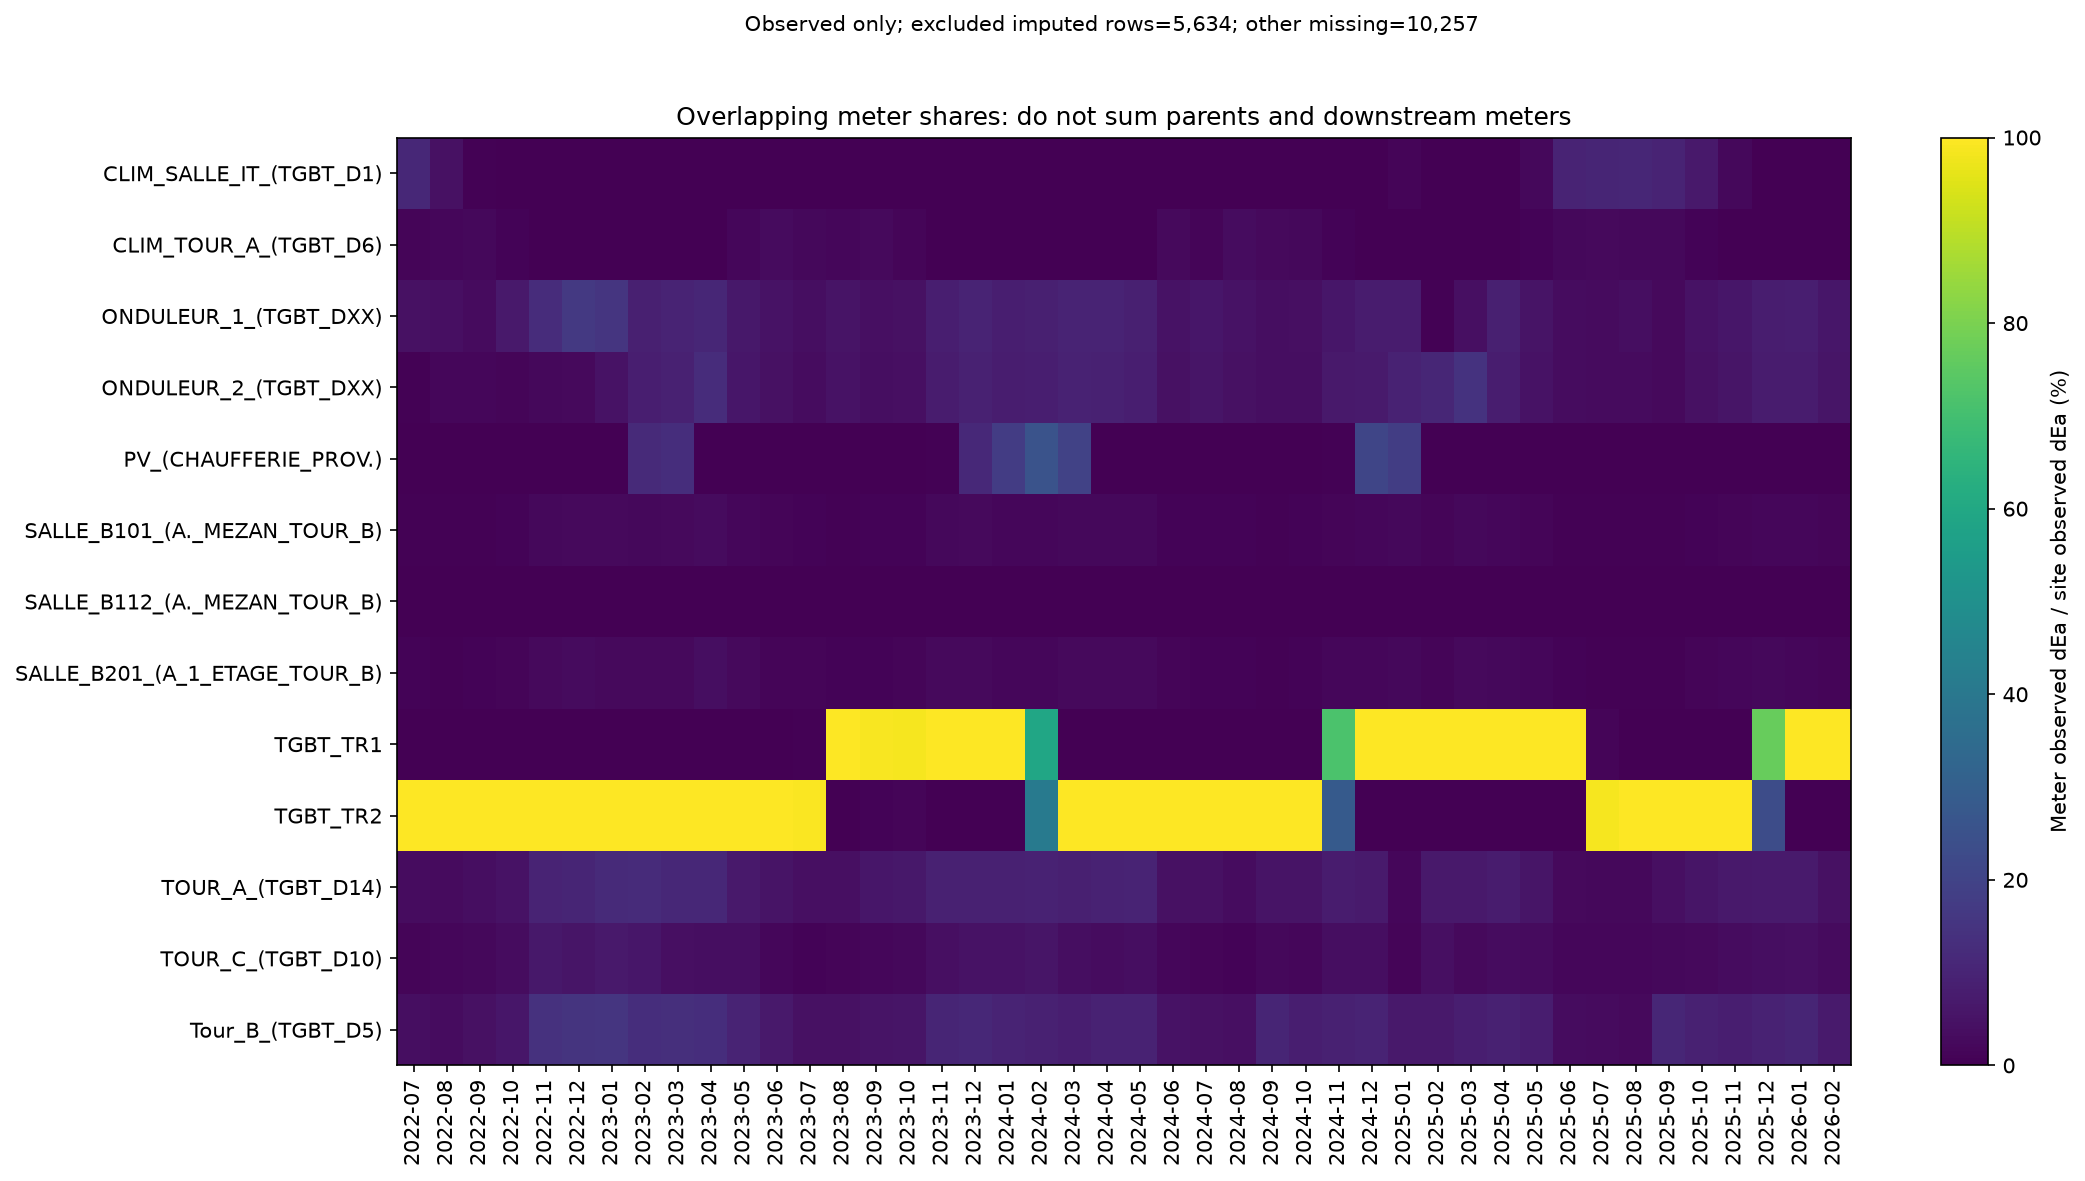

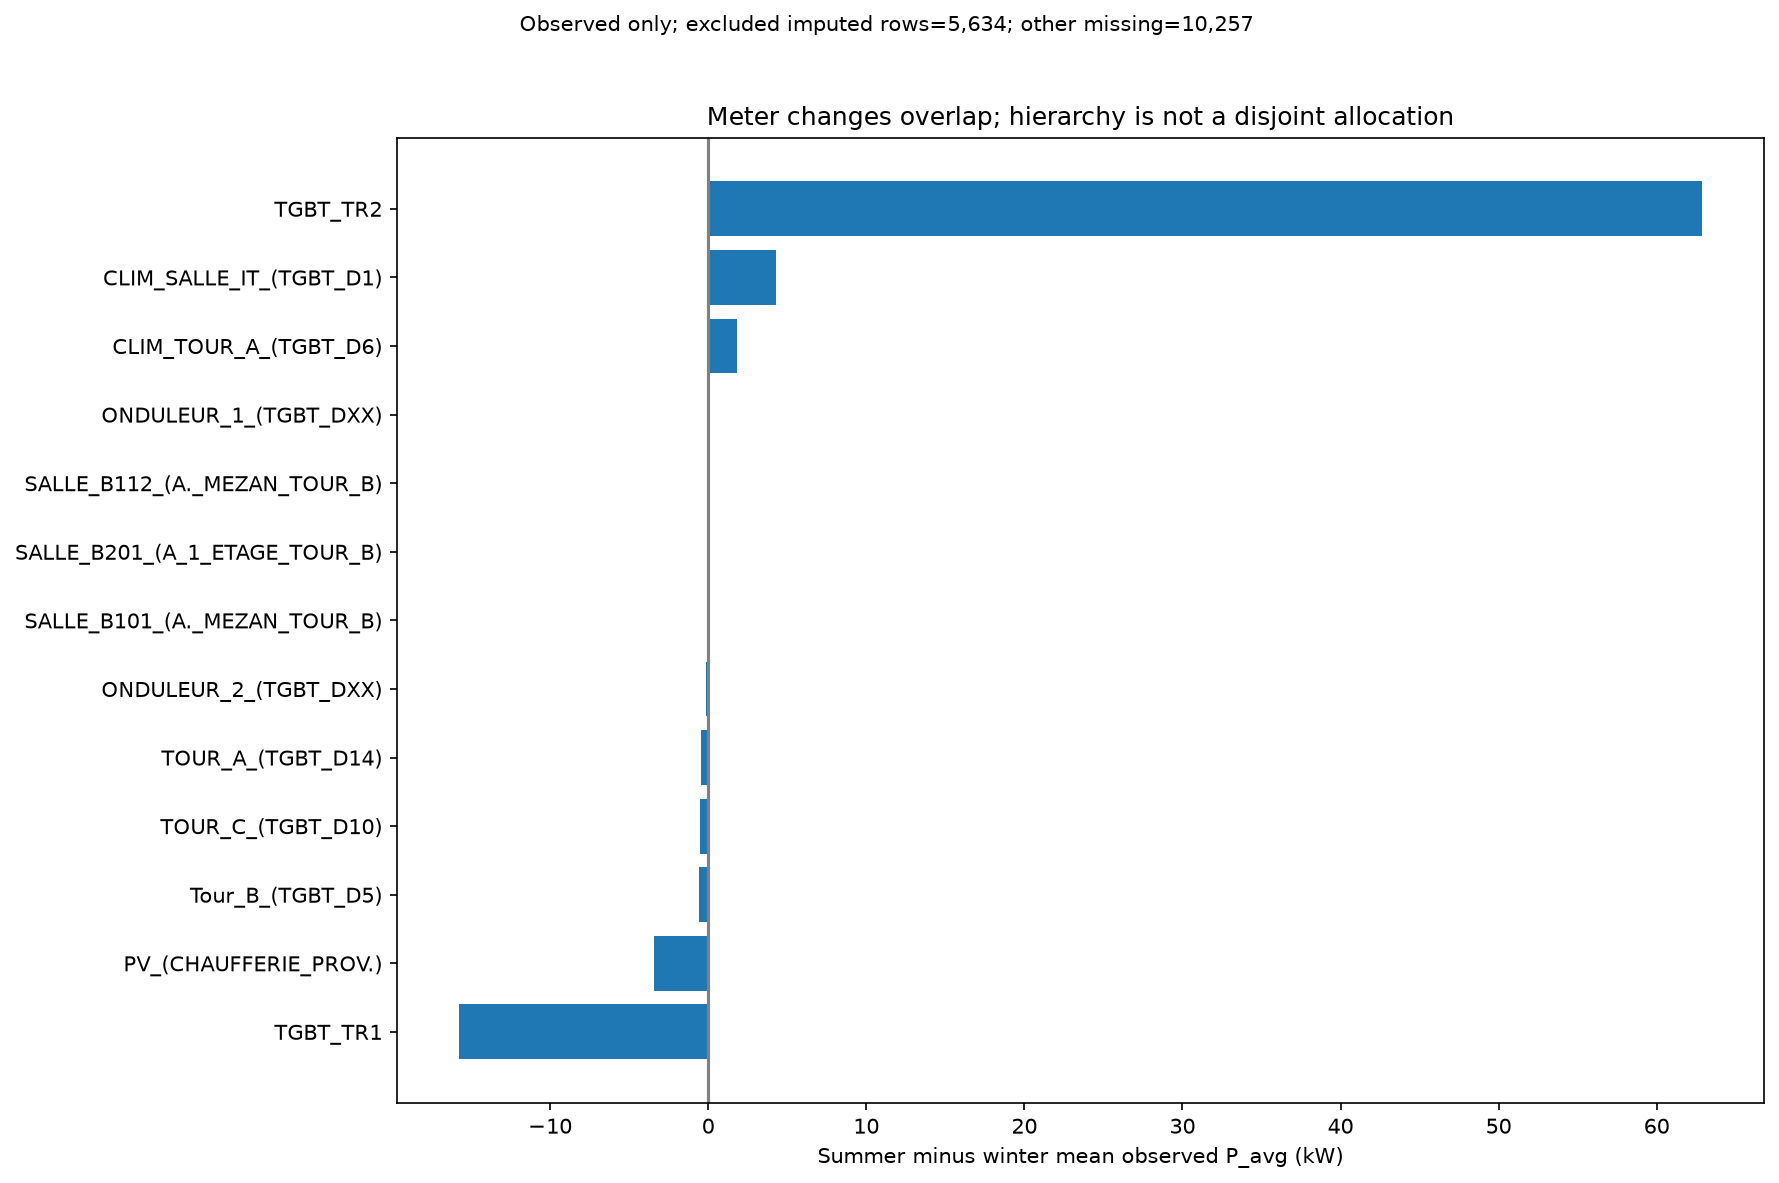

In [13]:
present(context, 'meter_contributions', meter_contributions(context.em, context.meters))

## D. Split feasibility counts only
No windows or model features are materialized. Imputed historical inputs are allowed; future labels must be observed.

In [14]:
present(context, 'splits', split_coverage(context.em))

splits: excluded imputed=377; other missing observed=1


## Written findings and provenance
All tables and figure references are generated by reusable functions in the report. Input Parquet hashes must remain unchanged.

In [15]:
write_eda_report(context)

Wrote reports/EDA.md; 14 figures at 150 dpi; input Parquet hashes unchanged.
